In [ ]:
# --- project root (added when the folder was organised): run notebooks from the project folder
import os, sys
from pathlib import Path
_p = Path.cwd()
while not (_p / "preprocess.py").exists() and _p != _p.parent:
    _p = _p.parent
os.chdir(_p); sys.path.insert(0, str(_p))
print("working folder:", _p)

# 08 — Step 5: training with targeted new regions (round 5)

**Change tested:** 11 new **training** regions aimed at the weakest cases found in 05b / 05c
(validation and test regions are unchanged, so results stay comparable):

| Gap found | New training regions |
|---|---|
| Snowy-winter farmland (Saskatchewan val) | Finland farmland, Manitoba, northern Kazakhstan |
| Savanna / shrubland (Serengeti val, Grass/Shrub on test) | Kruger (ZA), Ferlo (Senegal), Spanish dehesa |
| Inland seasonal wetland (Okavango test) | Inner Niger Delta (Mali), Lake Chad |
| Desert next to city (Las Vegas val) | Phoenix east, Riyadh outskirts |

Data: `data_r5/` (from `01c` + `02c`). Shared code: `train_lib_r5.py`.

| Run | = settings of | trained on |
|---|---|---|
| `C_segformer_v5` | `C_segformer_v4` (year channels) | `data_r5` |
| `C_segformer_v5b` | `C_segformer_v4b` (3-month window) | `data_r5` |
| `A_unet_v5` (optional, commented out) | `A_unet_v4` | `data_r5` |

After 05d you will know from step 4b which context type to keep; the other run can be dropped.
Finished runs are **skipped**, unfinished ones **resume**. Compare in **05d_compare_r5.ipynb**.

## 1. Setup

In [1]:
import importlib, subprocess, sys
if importlib.util.find_spec("segmentation_models_pytorch") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--user", "-q",
                           "--no-warn-script-location", "segmentation-models-pytorch"])
sys.path.append(".")
import gc, json, torch
from pathlib import Path
import train_lib_r5 as tl
from train_lib_r5 import DEV
print("torch", torch.__version__, "| device:", DEV)


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip


torch 2.9.1+cu128 | device: cuda


## 2. Experiment list

`BASE` = the settings used in 04a/b/c. Each experiment only lists what it changes (v4 = v2/v3 settings + year channels).
Comment out (`#`) any line you don't want to run now.

In [2]:
BASE = dict(
    DATA="data_r5", PRETRAINED=True, EPOCHS=40, WARMUP_EPOCHS=2, BATCH_SIZE=16, LR=3e-4,
    WEIGHT_DECAY=1e-4, PATIENCE=8, USE_CLASS_WEIGHTS=True, LOSS="dice", LABEL_SMOOTHING=0.0,
    NOISE_DB=1.0, MONTH_MIX=0.0, NUM_WORKERS=0, SEED=42, FEATURES="monthly",
)
LONGER_LOVASZ = dict(EPOCHS=60, PATIENCE=12, LOSS="lovasz")

YEAR = dict(FEATURES="monthly+year")
WINDOW = dict(FEATURES="monthly+window3")
SEGFORMER_V4 = dict(ARCH="segformer_mitb2", **LONGER_LOVASZ, LR=6e-5, WARMUP_EPOCHS=5,
                    WEIGHT_DECAY=0.01, NOISE_DB=2.0, MONTH_MIX=0.3)

EXPERIMENTS = [
    # ---- step 5: v4 / v4b settings, trained on data_r5 (11 extra training regions)
    dict(RUN_NAME="C_segformer_v5",  GROUP="C_segformer_v5",
         MODEL_NAME="SegFormer / MiT-B2 v5 (+year, more regions)", **SEGFORMER_V4, **YEAR),
    dict(RUN_NAME="C_segformer_v5b", GROUP="C_segformer_v5b",
         MODEL_NAME="SegFormer / MiT-B2 v5b (+3-month window, more regions)", **SEGFORMER_V4, **WINDOW),
    # dict(RUN_NAME="A_unet_v5", GROUP="A_unet_v5", ARCH="unet_resnet34",
    #      MODEL_NAME="U-Net / ResNet-34 v5 (+year, more regions)", **LONGER_LOVASZ, **YEAR),
]
for e in EXPERIMENTS:
    print(f"{e['RUN_NAME']:18s} {e['ARCH']:24s} " + ", ".join(f"{k}={v}" for k, v in e.items()
          if k not in ("RUN_NAME", "GROUP", "ARCH", "MODEL_NAME") and BASE.get(k) != v))

C_segformer_v5     segformer_mitb2          EPOCHS=60, PATIENCE=12, LOSS=lovasz, LR=6e-05, WARMUP_EPOCHS=5, WEIGHT_DECAY=0.01, NOISE_DB=2.0, MONTH_MIX=0.3, FEATURES=monthly+year
C_segformer_v5b    segformer_mitb2          EPOCHS=60, PATIENCE=12, LOSS=lovasz, LR=6e-05, WARMUP_EPOCHS=5, WEIGHT_DECAY=0.01, NOISE_DB=2.0, MONTH_MIX=0.3, FEATURES=monthly+window3


## 3. Validation set (loaded once)
The context-channel statistics (`norm_stats_year.json` / `norm_stats_window3.json` in the data folder) are computed automatically by the first run that needs them, from the training patches only.

In [3]:
import shutil
_tmp, DATA, stats, index = tl.setup(dict(BASE, RUN_NAME="_tmp")); shutil.rmtree(_tmp)
val_ds = tl.EvalPatches(index[index.split == "val"].file, DATA, desc="loading val")
print("val regions:", sorted(index[index.split == "val"].region.unique()))
print("train patches:", (index.split == "train").sum(), "| val patches:", (index.split == "val").sum())

device: cuda | GPU: NVIDIA RTX A6000, 50.9 GB


loading val:   0%|          | 0/128 [00:00<?, ?it/s]

val regions: ['bangkok', 'danube_delta', 'iowa', 'las_vegas', 'madrid', 'saskatchewan', 'serengeti', 'sudd_wetland']
train patches: 950 | val patches: 128


## 4. Run all experiments
For each experiment: setup → data → model → sanity check → training → curves → validation results.


C_segformer_v5  —  SegFormer / MiT-B2 v5 (+year, more regions)
device: cuda | GPU: NVIDIA RTX A6000, 50.9 GB


year-channel stats:   0%|          | 0/950 [00:00<?, ?it/s]

train patches 950 | val samples 1536 (128 patches x 12 months)


config.json:   0%|          | 0.00/135 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/98.9M [00:00<?, ?B/s]

24.7 M parameters | encoder weights: imagenet | loss: CE + lovasz | input channels: 7
step  0  loss 3.132
step 10  loss 0.614
step 20  loss 0.529
step 29  loss 0.449


... (54 outputs left out)

epoch 27:   0%|          | 0/59 [00:00<?, ?it/s]

ep 27 | train 0.566 | val 1.282 | OA 0.800 | mIoU 0.595 | 78s


epoch 28:   0%|          | 0/59 [00:00<?, ?it/s]

ep 28 | train 0.565 | val 1.255 | OA 0.803 | mIoU 0.603 | 77s
Early stopping.
Done. Best val mIoU: 0.6264


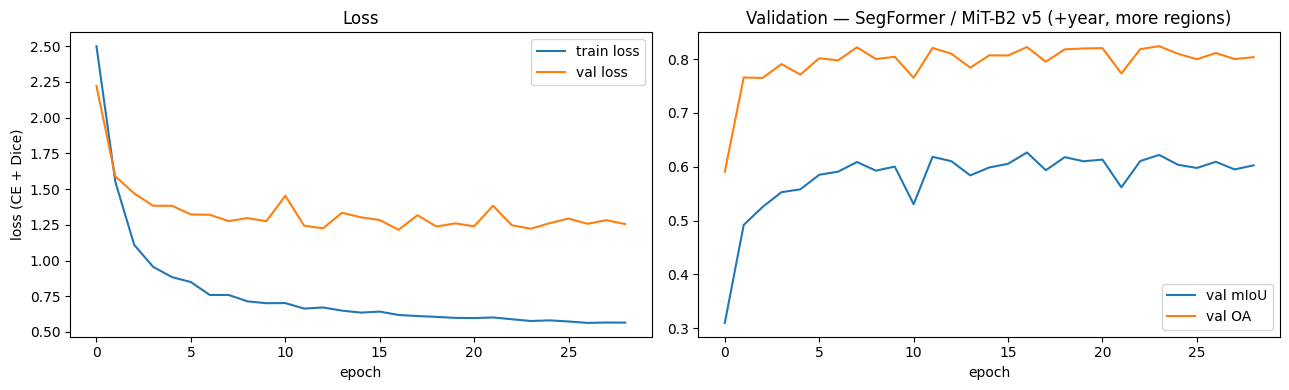

SegFormer / MiT-B2 v5 (+year, more regions): val OA 0.822 | val mIoU 0.626 | 24.7 M params | 39.8 min


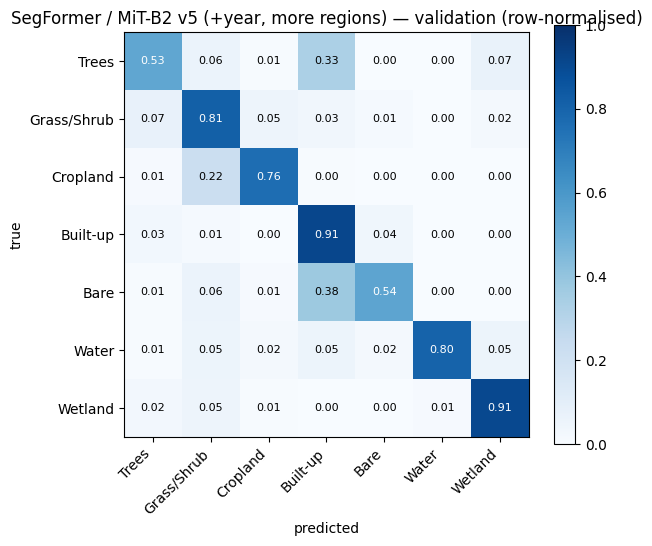

,IoU,F1
Trees,0.413,0.584
Grass/Shrub,0.676,0.807
Cropland,0.661,0.796
Built-up,0.780,0.877
Bare,0.266,0.420
Water,0.737,0.849
Wetland,0.851,0.920
mean,0.626,0.750



C_segformer_v5b  —  SegFormer / MiT-B2 v5b (+3-month window, more regions)
device: cuda | GPU: NVIDIA RTX A6000, 50.9 GB


window3-channel stats:   0%|          | 0/950 [00:00<?, ?it/s]

train patches 950 | val samples 1536 (128 patches x 12 months)
24.7 M parameters | encoder weights: imagenet | loss: CE + lovasz | input channels: 7
step  0  loss 3.123
step 10  loss 0.650
step 20  loss 0.562
step 29  loss 0.470


epoch 0:   0%|          | 0/59 [00:00<?, ?it/s]

ep  0 | train 2.567 | val 2.253 | OA 0.586 | mIoU 0.295  *best* | 70s


... (56 outputs left out)

epoch 29:   0%|          | 0/59 [00:00<?, ?it/s]

ep 29 | train 0.660 | val 1.381 | OA 0.780 | mIoU 0.560 | 71s


epoch 30:   0%|          | 0/59 [00:00<?, ?it/s]

ep 30 | train 0.659 | val 1.385 | OA 0.777 | mIoU 0.548 | 71s
Early stopping.
Done. Best val mIoU: 0.5804


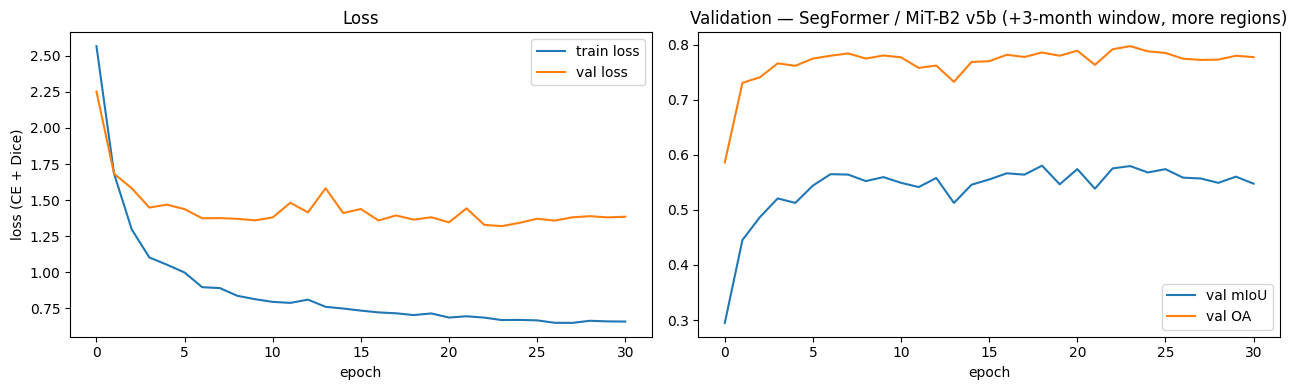

SegFormer / MiT-B2 v5b (+3-month window, more regions): val OA 0.786 | val mIoU 0.580 | 24.7 M params | 36.7 min


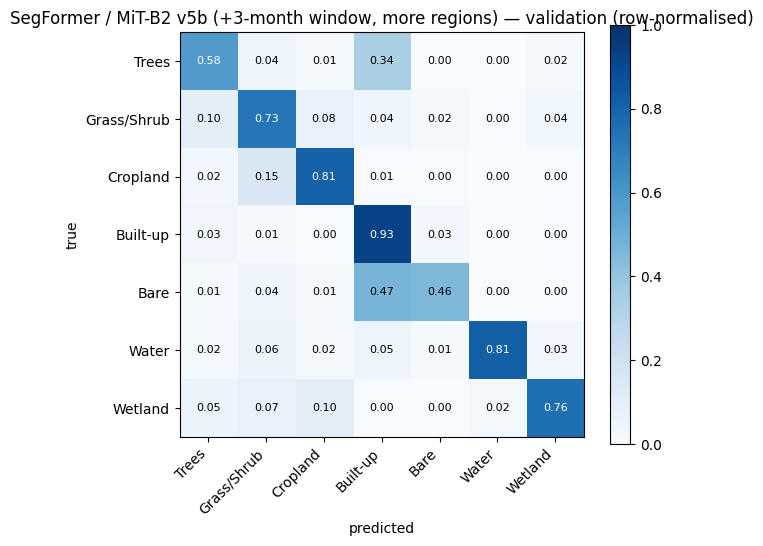

,IoU,F1
Trees,0.410,0.582
Grass/Shrub,0.616,0.763
Cropland,0.574,0.730
Built-up,0.783,0.879
Bare,0.256,0.408
Water,0.707,0.829
Wetland,0.715,0.834
mean,0.580,0.718


In [4]:
summary = []
for exp in EXPERIMENTS:
    CFG = dict(BASE, **exp)
    RUN = Path("runs") / CFG["RUN_NAME"]
    print("\n" + "=" * 90 + f"\n{CFG['RUN_NAME']}  —  {CFG['MODEL_NAME']}\n" + "=" * 90)
    if (RUN / "metrics.json").exists():
        m = json.load(open(RUN / "metrics.json"))
        print(f"already finished -> skipped (val mIoU {m['val_miou']:.3f})")
        summary.append(m); continue

    RUN, DATA, stats, index = tl.setup(CFG)
    train_dl, val_dl = tl.make_loaders(CFG, DATA, stats, index, val_ds=val_ds)
    model, CFG["WEIGHTS_USED"] = tl.build_pretrained(CFG["ARCH"], CFG["PRETRAINED"], tl.in_channels_of(CFG))
    json.dump(CFG, open(RUN / "config.json", "w"), indent=2)
    model = model.to(DEV)
    loss_fn = tl.make_loss(CFG, stats)
    print(f"{tl.count_params(model):.1f} M parameters | encoder weights: {CFG['WEIGHTS_USED']} | loss: CE + {CFG['LOSS']} | input channels: {tl.in_channels_of(CFG)}")
    if not (RUN / "last.pth").exists():
        tl.overfit_one_batch(model, loss_fn, train_dl, steps=30, lr=CFG["LR"] * 3)

    tl.train(model, CFG, RUN, train_dl, val_dl, loss_fn)
    tl.plot_curves(RUN, CFG["MODEL_NAME"])
    display(tl.final_validation(model, CFG, RUN, val_dl))
    summary.append(json.load(open(RUN / "metrics.json")))

    del model, train_dl; gc.collect()
    if DEV == "cuda": torch.cuda.empty_cache()

## 5. Summary of this notebook's runs

In [5]:
import pandas as pd
tab = pd.DataFrame([{"run": m["run"], "val OA": m["val_oa"], "val mIoU": m["val_miou"],
                     "best epoch": m["best_epoch"], "epochs": m["epochs_run"], "min": m["train_minutes"]}
                    for m in summary]).set_index("run").sort_values("val mIoU", ascending=False)
display(tab)
print("Now run 05d_compare_r5.ipynb to compare with all earlier runs on the same validation and test sets.")

,val OA,val mIoU,best epoch,epochs,min
run,,,,,
C_segformer_v5,0.8222,0.6264,16,29,39.8
C_segformer_v5b,0.7859,0.5804,18,31,36.7


Now run 05d_compare_r5.ipynb to compare with all earlier runs on the same validation and test sets.


## 6. Save results

In [ ]:
import shutil
for m in summary:
    shutil.make_archive(f"{m['run']}_results", "zip", Path("runs") / m["run"])
    print("zipped:", f"{m['run']}_results.zip")